# Week 10 - DSMC data-driven surrogates: reproduce, test, and critique

MIE690A article-aligned validation v4

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week10/W10_DSMC_Data_Driven_Surrogates_Student.ipynb)

This lab rebuilds numerical results from Roohi and Shoja-Sani, *Data-driven surrogate modeling of DSMC solutions using deep neural networks*, Aerospace Science and Technology 168 (2026) 110785, DOI `10.1016/j.ast.2025.110785`.

**Learning outcomes**

1. explain the DSMC move-collide-sample cycle and its resolution checks;
2. audit complete raw numerical tables and their checksums;
3. test log-Knudsen parametric synthesis between supplied cavity fields;
4. build a POD-polynomial profile surrogate for monatomic and diatomic shocks;
5. distinguish interpolation from extrapolation and representation error from field error; and
6. report unavailable targets instead of replacing them with a plotted image.

Runtime: CPU, normally under two minutes after installation.

### Before running

Use Python 3.12 or 3.13 with the repository constraints (NumPy 2.0–2.2). [Environment setup and evidence terminology](../../docs/STUDENT_EXECUTION_GUIDE.md). A classical baseline may win; that is a valid result. Read the mode printed by each experiment before describing a retained table as your own training run.

## Trace every figure to the run that produced it
Retained author figures document a fixed experiment. Newly regenerated figures
must be displayed from the fresh output directory, next to that run's metrics.
The default cavity reproduction interpolates fields in log Knudsen number; it
does not retrain the article's per-Knudsen MLPs.

For two training Knudsen numbers $Kn_a,Kn_b$, the interpolation weight is

$$
w=\frac{\log Kn-\log Kn_a}{\log Kn_b-\log Kn_a},\qquad
q=(1-w)q_a+wq_b.
$$

$q$ is a field and $w$ is dimensionless. This is interpolation for $0\le w\le1$;
outside that interval it is extrapolation. Verify the weight by substitution.
For error $\|q-\hat q\|_2/S$, state the scale $S$. A velocity-component error
normalized by the lid speed can look small while its component-relative error
is large. Neither normalization may be silently substituted for the other.
Also inspect heat flux, stress and translational-temperature overshoot: matching
density alone does not validate nonequilibrium shock structure.

## Scientific contract

The raw cavity and shock tables are committed under `data/aescte_dsmc/raw/`. The notebook never digitizes a paper raster. Training cases and assessment cases remain case-wise separated.

The attached cavity fields contain lid speeds **10 and 30 m/s**. Although the paper also discusses 100 m/s, that raw target was not supplied. The diatomic archive ends at Mach 1.9; therefore the published Mach-2 plot cannot be independently scored here. These boundaries are part of the result.

In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
# Colab/local bootstrap
from pathlib import Path as _Path
import os as _os, subprocess as _subprocess, sys as _sys

if "google.colab" in _sys.modules:
    _root = _Path("/content/FlowMLLab")
    if not (_root / ".git").is_dir():
        _subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Ehsan-Roohi/FlowMLLab.git", str(_root)], check=True)
    _subprocess.run([_sys.executable, "-m", "pip", "install", "-q", "-e", str(_root)], check=True)
    _os.chdir(_root / "notebooks/week10")

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
RESULTS = REPO_ROOT / "results/aescte_dsmc"
if str(REPO_ROOT) not in _sys.path:
    _sys.path.insert(0, str(REPO_ROOT))
print("FlowMLLab:", REPO_ROOT)
print("Python:", _sys.version.split()[0])

FlowMLLab: <repository>
Python: 3.12.14


## 1. What DSMC computes

For each time step, a DSMC solver:

1. moves representative particles ballistically;
2. applies wall/inlet/outlet interactions;
3. selects collision pairs locally (Bird NTC here);
4. redistributes translational and internal energy using a molecular model; and
5. samples macroscopic moments only after the transient.

A defensible dataset requires cell size relative to mean free path, time step relative to collision time, particles per cell, sampling duration, and repeat-seed uncertainty. A visually smooth contour is not itself CFD validation.

In [2]:
from flowmllab.aescte_dsmc import (
    CAVITY_LID_SPEEDS_MS, CAVITY_TEST_KNUDSEN,
    cavity_case, fit_pod_polynomial_operator,
    load_cavity_archive, load_shock_archive,
    logarithmic_kn_prediction, maxwell_speed_pdf,
    normalized_rmse, predict_pod_polynomial_operator,
    relative_l2, sha256, linear_profile_prediction, SHOCK_RELATIVE_L2_GATE_PERCENT,
)

manifest = json.loads((RESULTS / "data_manifest.json").read_text())
display(pd.DataFrame([manifest["raw_data_contract"]]).T.rename(columns={0: "value"}))
print("tracked raw files:", len(manifest["source_file_sha256"]))
print("manifest SHA-256:", sha256(RESULTS / "data_manifest.json"))

,value
cavity_cases,14
cavity_grid,"[50, 50]"
diatomic_profile_points,300
diatomic_shock_cases,6
knudsen_numbers,"[0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 10.0]"
lid_speeds_in_attached_data_ms,"[10, 30]"
monatomic_profile_points,300
monatomic_shock_cases,7
sparta_input_sets,"[0.01, 0.05, 0.5, 1.0]"


tracked raw files: 85
manifest SHA-256: 455991685839806877a5456b2e0af3abf6340d568fa6fd79c668273e02e681ab


## 2. Rarefied cavity: the family-of-specialists construction

Reference solutions are available at

$$
Kn=10^{-3},10^{-2},10^{-1},1,10.
$$

The **article's cavity model is not DeepONet**. It trains one coordinate MLP
for each available $Kn$: $(x,y)$ first pass through fixed random Fourier
features (scale 2.5), followed by three 256-unit Swish layers and a linear
field-output layer. Dropout of 0.2 follows the first two hidden layers and the
reported regularization is $L_2=10^{-6}$. Neighboring specialist predictions
are then fused in log-$Kn$. DeepONet is used in the article's separate
diatomic-shock experiment.

For a held-out value bracketed by $Kn_l$ and $Kn_u$, that fusion rule is

$$
w=\frac{\log_{10}Kn_* - \log_{10}Kn_l}{\log_{10}Kn_u-\log_{10}Kn_l},\qquad
\widehat q_*=(1-w)q_l+wq_u.
$$

In this **course reproduction**, however, $q_l$ and $q_u$ are the complete
supplied DSMC fields, not outputs of retrained article MLPs. Thus the reported
sub-2% result measures direct log-Kn field interpolation and must not be
reported as MLP or DeepONet accuracy.

In [3]:
cavity = load_cavity_archive(RESULTS / "cavity_fields_14cases.npz")
print("temperature tensor:", cavity["temperature_k"].shape)
print("lid speeds:", np.unique(cavity["lid_speed_ms"]))
print("Kn values:", np.unique(cavity["knudsen"]))

cavity_rows = []
cavity_predictions = {}
for lid in CAVITY_LID_SPEEDS_MS:
    for kn in CAVITY_TEST_KNUDSEN:
        pred = logarithmic_kn_prediction(cavity, lid_speed_ms=lid, test_knudsen=kn)
        cavity_predictions[(int(lid), float(kn))] = pred
        target = cavity_case(cavity, lid, kn)
        for field, scale in (("u_ms", lid), ("v_ms", lid), ("temperature_k", 50.0)):
            cavity_rows.append({
                "U_lid_m/s": int(lid), "held_out_Kn": kn, "field": field,
                "NRMSE_percent": normalized_rmse(cavity[field][target], pred[field], scale),
            })
cavity_metrics = pd.DataFrame(cavity_rows)
display(cavity_metrics)
assert cavity_metrics.NRMSE_percent.max() < 2.0

temperature tensor: (14, 50, 50)
lid speeds: [10. 30.]
Kn values: [1.e-03 1.e-02 5.e-02 1.e-01 5.e-01 1.e+00 1.e+01]


,U_lid_m/s,held_out_Kn,field,NRMSE_percent
0,10,0.05,u_ms,0.895304
1,10,0.05,v_ms,1.281102
2,10,0.05,temperature_k,0.534615
3,10,0.50,u_ms,0.811630
4,10,0.50,v_ms,0.783719
5,10,0.50,temperature_k,0.463208
6,30,0.05,u_ms,0.567734
7,30,0.05,v_ms,0.519856
8,30,0.05,temperature_k,0.584345
9,30,0.50,u_ms,0.622141


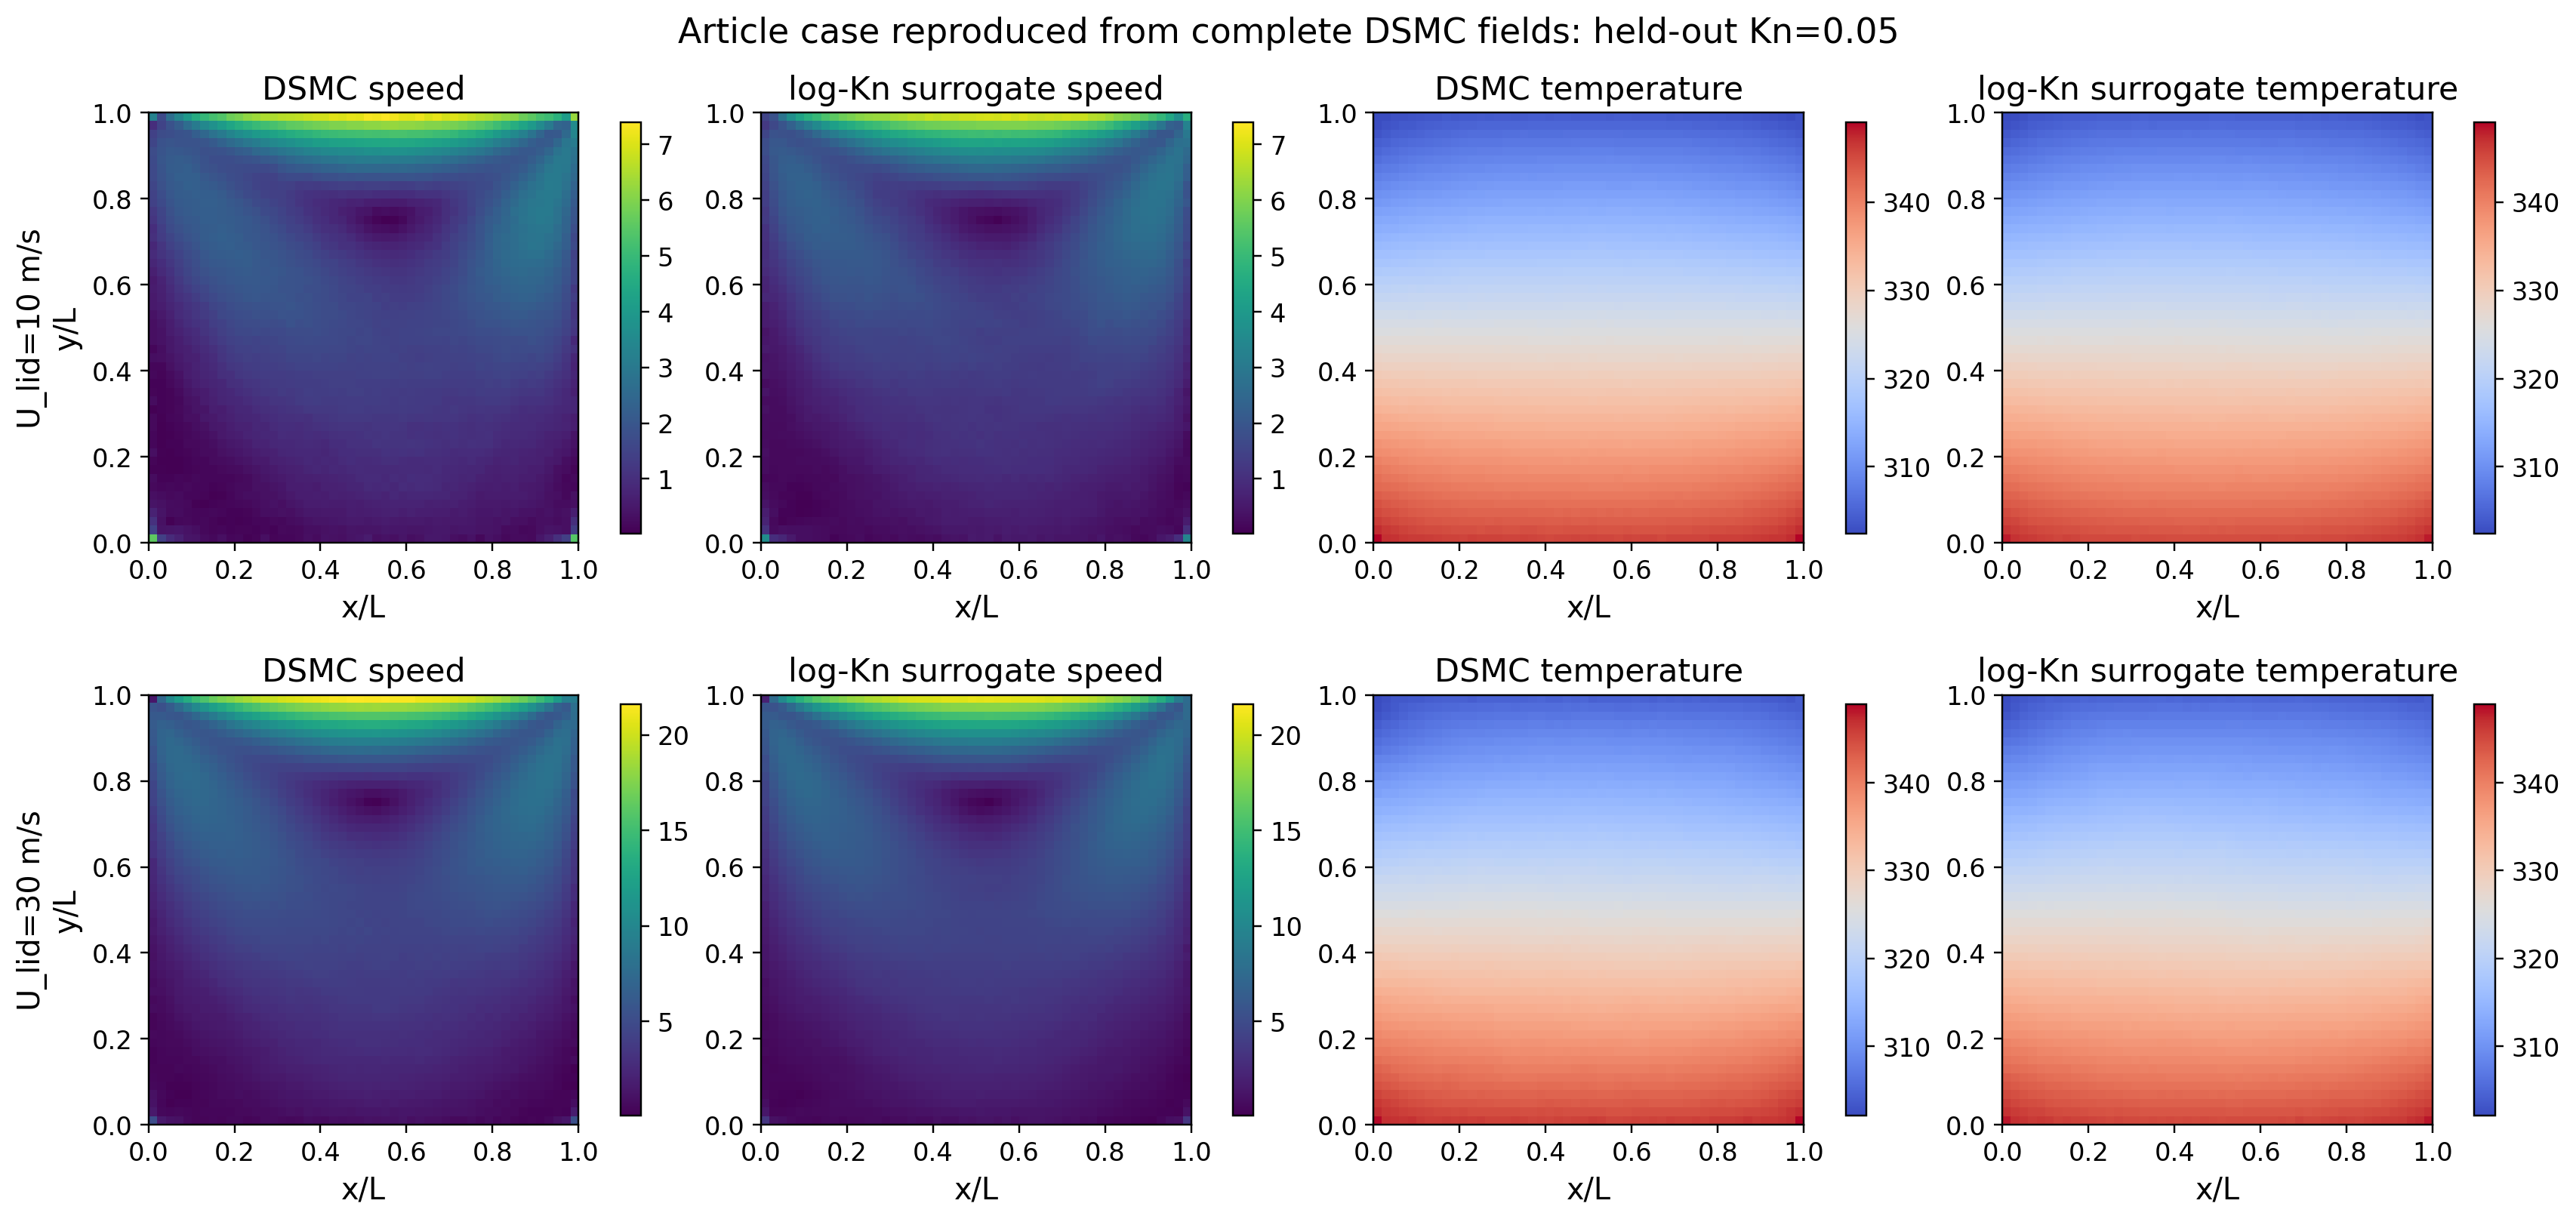

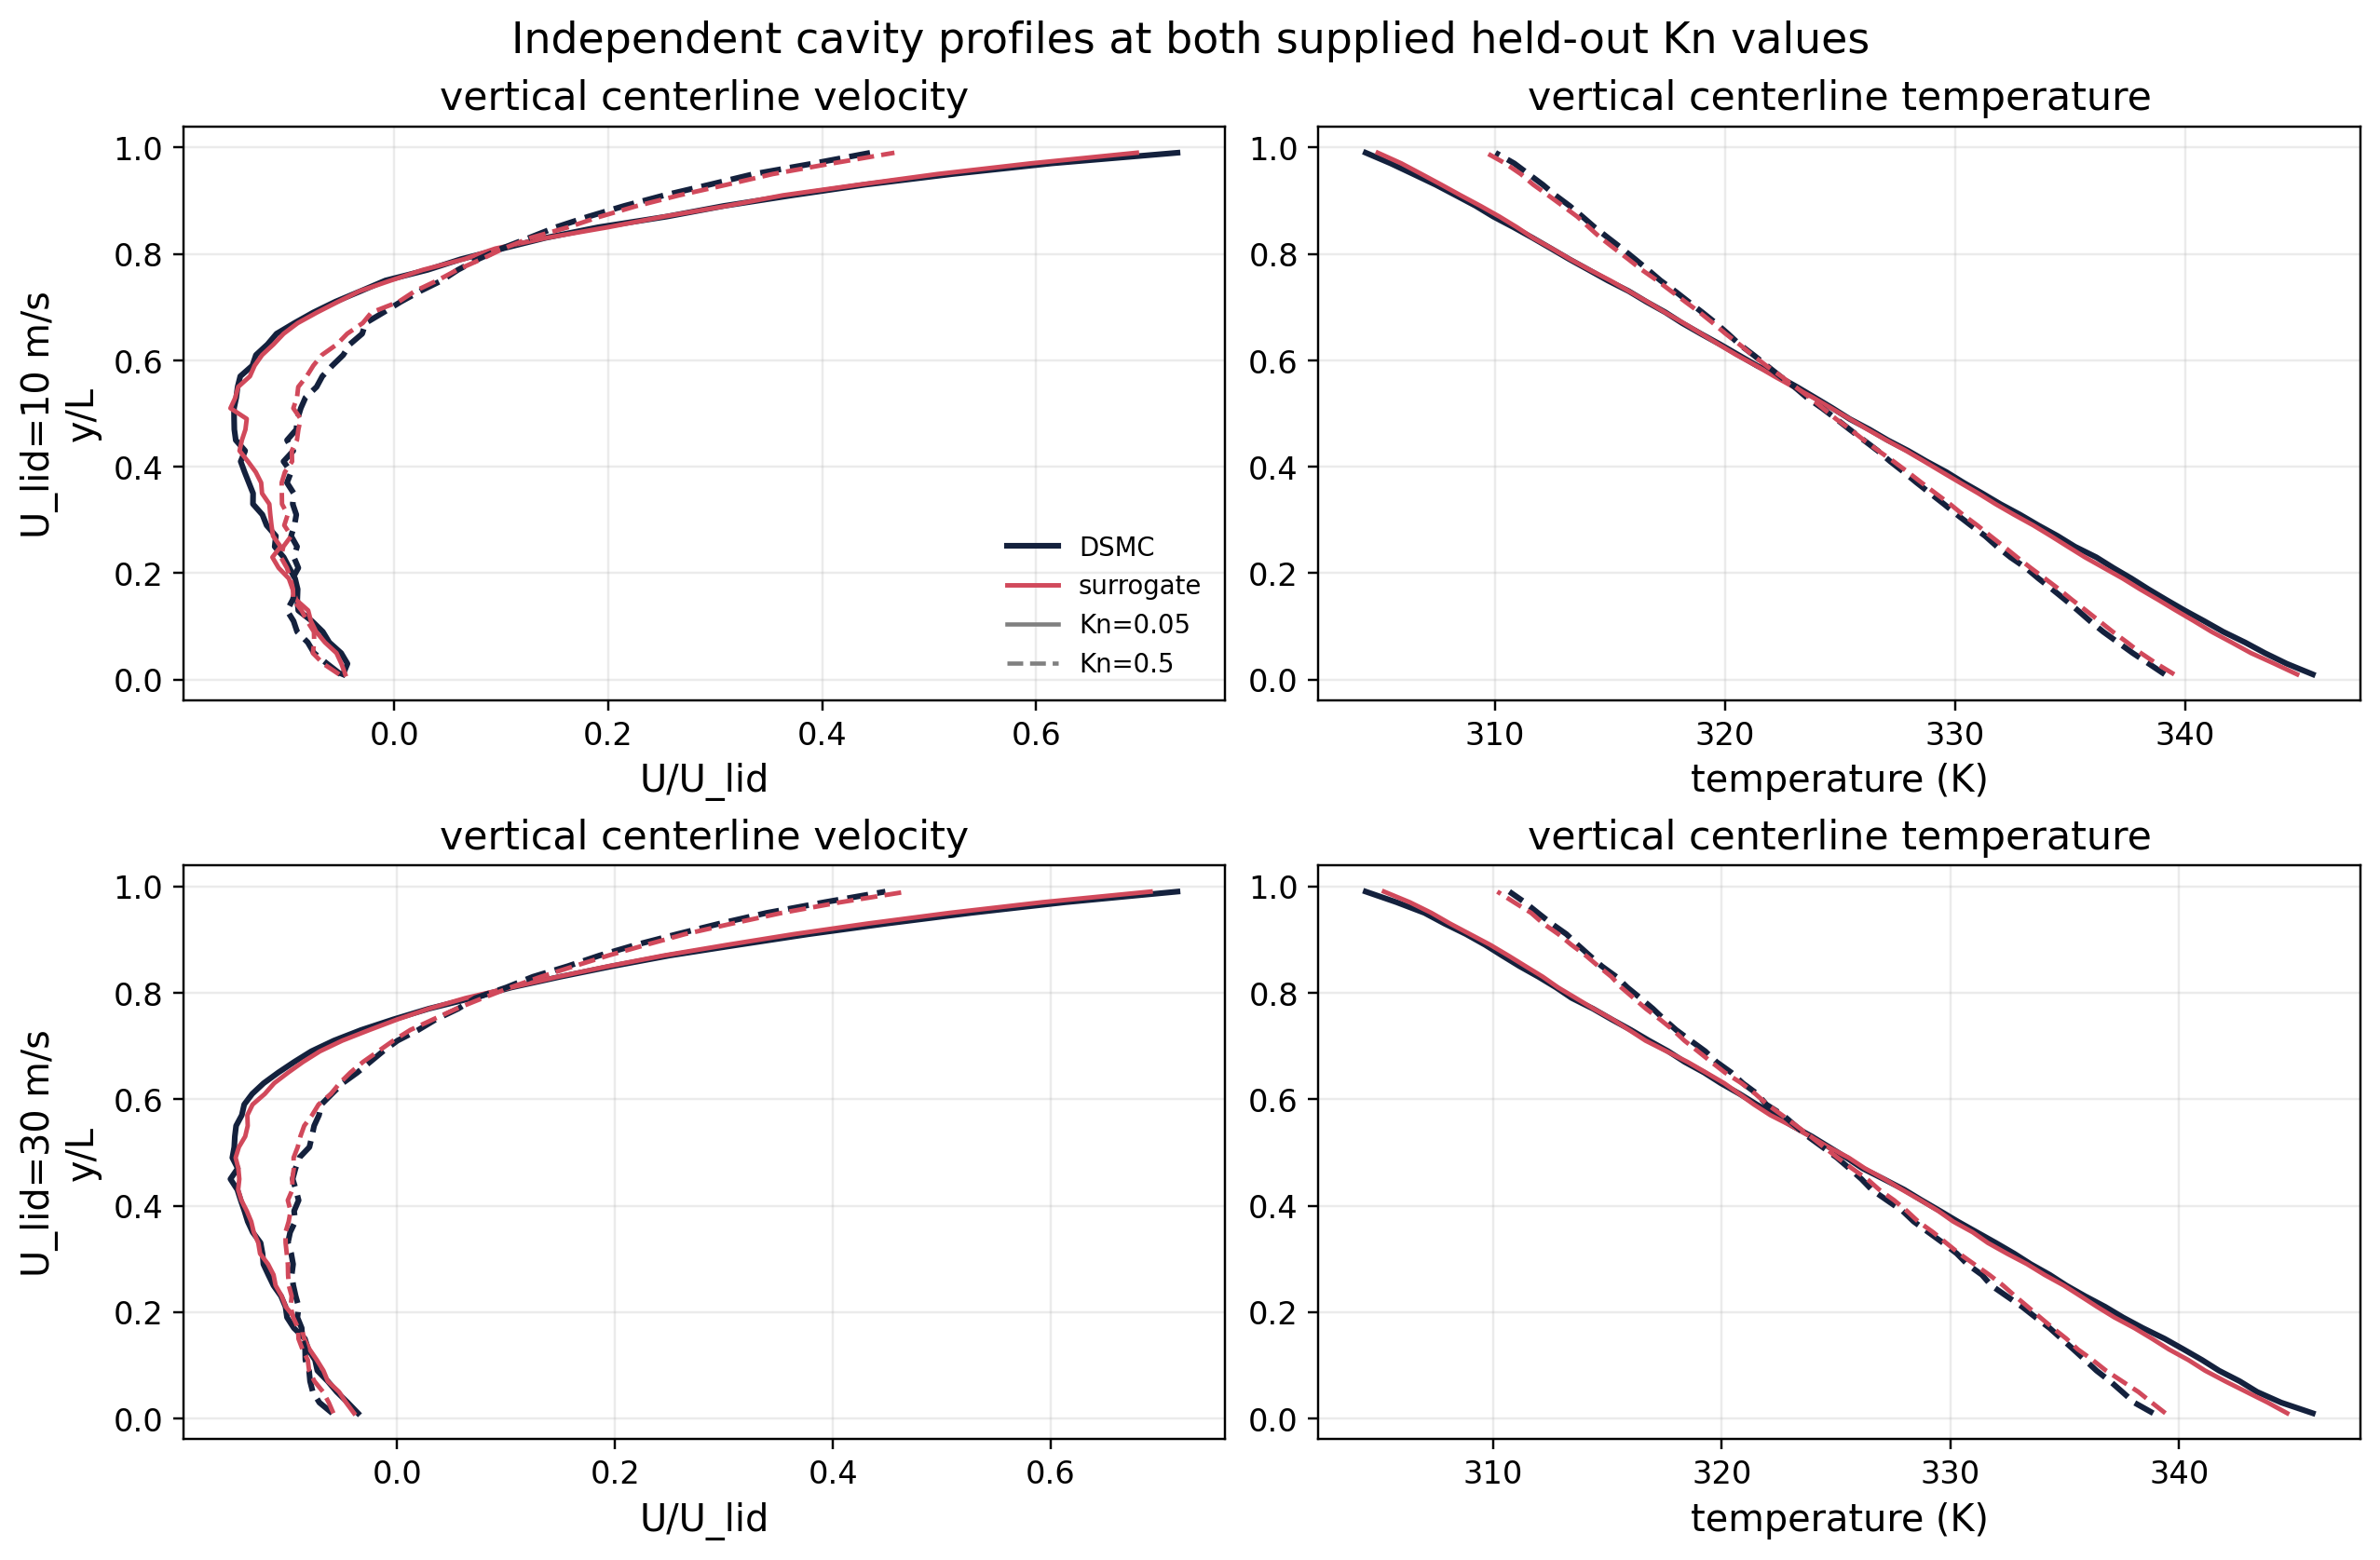

In [4]:
display(Image(filename=str(RESULTS / "cavity_kn005_reproduction.png")))
display(Image(filename=str(RESULTS / "cavity_validation_profiles.png")))

### Interpret the metric

Velocity RMSE is normalized by lid speed and temperature RMSE by the 50 K wall-temperature difference. Component-wise relative $L_2$ can look large for $V$ because its reference norm is small. Always state the denominator.

The retained primary-variable gate is below 2% for every supplied held-out cavity case. Heat flux and stress are also reported in the machine-readable CSV, but are harder because DSMC moment noise grows with moment order.

## 3. Diatomic nitrogen shock: delayed internal relaxation

The six source profiles correspond to Mach 1.4--1.9. The original filenames (`M14.5` ... `M19.5`) are preserved; the trailing `.5` is a DSMC internal-setting suffix, not Mach 14.5.

The teaching profile surrogate uses POD modes $t_k(x)$ and polynomial Mach
coefficients $b_k(M)$:

$$
\widehat q(M,x)=\bar q(x)+\sum_{k=1}^{r} b_k(M)t_k(x).
$$

Mach 1.7 is removed for interpolation (rank 4, degree 3). Mach 1.4 is then
removed and predicted from Mach 1.5--1.9 for extrapolation (rank 4, degree 2).
These are the fixed retained demonstration settings, not an optimality claim.
The shared diatomic acceptance gate is 1.5% profile-relative L2. The linear
neighbor baseline uses exactly the same training cases; compare both per field.
Explain why a lower polynomial degree can reduce extrapolation instability,
then propose a development-only selection protocol before trying alternatives.

In [5]:
diatomic = load_shock_archive(RESULTS / "diatomic_shock_6cases.npz")
shock_fields = ["rotational_temperature", "translational_temperature", "normalized_velocity"]

def predict_shock(test_mach, training_mach, rank, degree):
    train = np.flatnonzero(np.isin(np.round(diatomic["mach"], 8), np.round(training_mach, 8)))
    out = {}
    for field in shock_fields:
        model = fit_pod_polynomial_operator(diatomic["mach"], diatomic[field], train, rank=rank, degree=degree)
        out[field] = predict_pod_polynomial_operator(model, [test_mach])[0]
    return out

pred_17 = predict_shock(1.7, [1.4, 1.5, 1.6, 1.8, 1.9], rank=4, degree=3)
pred_14 = predict_shock(1.4, [1.5, 1.6, 1.7, 1.8, 1.9], rank=4, degree=2)

rows = []
for mach, pred, kind in ((1.7, pred_17, "interpolation"), (1.4, pred_14, "extrapolation")):
    target = int(np.flatnonzero(np.isclose(diatomic["mach"], mach))[0])
    for field in shock_fields:
        rows.append({"task": kind, "Mach": mach, "field": field,
                     "relative_L2_percent": relative_l2(diatomic[field][target], pred[field])})
shock_metrics = pd.DataFrame(rows)
display(shock_metrics)
assert shock_metrics.relative_L2_percent.max() < SHOCK_RELATIVE_L2_GATE_PERCENT
# Matched-data control: the same permitted Mach profiles, no fitted POD basis.
linear_rows = []
for mach, training_mach, kind in [(1.7, [1.4,1.5,1.6,1.8,1.9], 'interpolation'),
                                  (1.4, [1.5,1.6,1.7,1.8,1.9], 'extrapolation')]:
    train = np.flatnonzero(np.isin(np.round(diatomic['mach'],8), training_mach))
    target = int(np.flatnonzero(np.isclose(diatomic['mach'],mach))[0])
    for field in shock_fields:
        estimate = linear_profile_prediction(diatomic['mach'][train], diatomic[field][train], mach)
        linear_rows.append({'task':kind, 'Mach':mach, 'field':field,
                            'linear_relative_L2_percent':relative_l2(diatomic[field][target], estimate)})
display(shock_metrics.merge(pd.DataFrame(linear_rows), on=['task','Mach','field']))

,task,Mach,field,relative_L2_percent
0,interpolation,1.7,rotational_temperature,0.142170
1,interpolation,1.7,translational_temperature,0.259715
2,interpolation,1.7,normalized_velocity,0.291046
3,extrapolation,1.4,rotational_temperature,0.630034
4,extrapolation,1.4,translational_temperature,1.018425
5,extrapolation,1.4,normalized_velocity,0.925601


,task,Mach,field,relative_L2_percent,linear_relative_L2_percent
0,interpolation,1.7,rotational_temperature,0.142170,0.240721
1,interpolation,1.7,translational_temperature,0.259715,0.369228
2,interpolation,1.7,normalized_velocity,0.291046,0.328905
3,extrapolation,1.4,rotational_temperature,0.630034,0.877348
4,extrapolation,1.4,translational_temperature,1.018425,1.175440
5,extrapolation,1.4,normalized_velocity,0.925601,1.068272


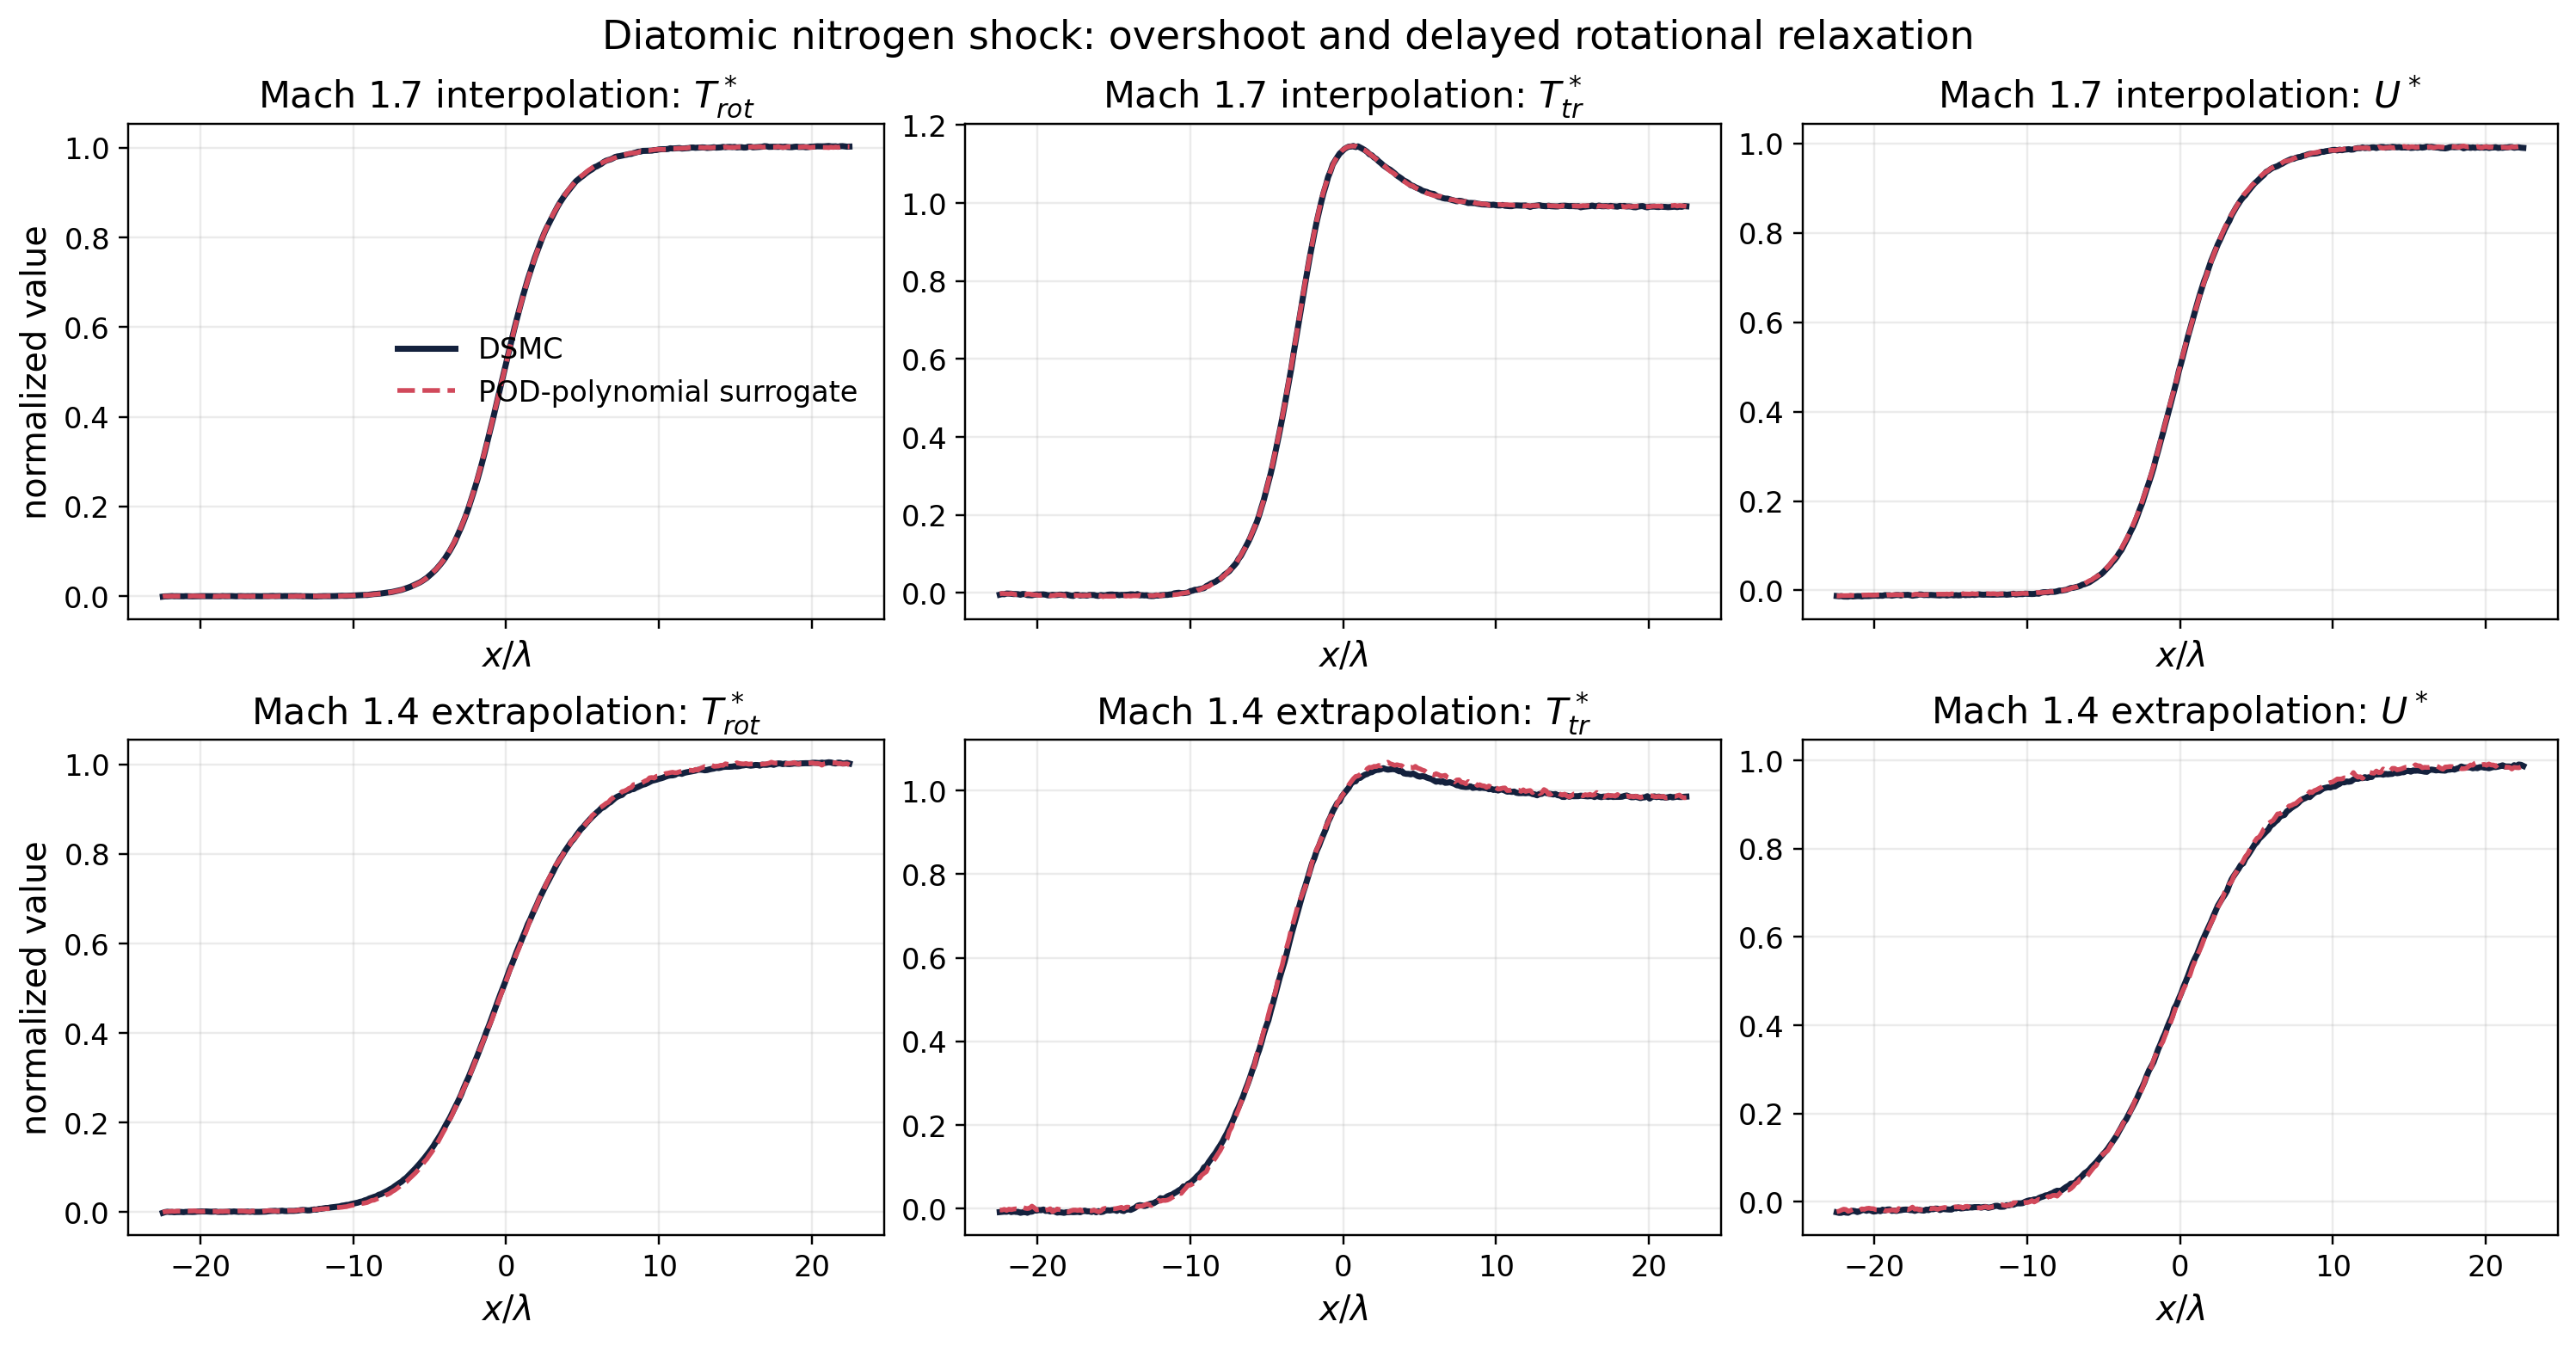

In [6]:
display(Image(filename=str(RESULTS / "diatomic_shock_reproduction.png")))

The translational-temperature overshoot is the key nonequilibrium feature: translational energy rises rapidly at the shock and then relaxes into the rotational mode. Matching only upstream and downstream plateaus would miss this physics.

The result is strongest for interpolation. Mach-1.4 retained extrapolation was below 1.1% (the fixed acceptance gate is 1.5%) profile-relative $L_2$, but the Mach-2 article case is marked unavailable because the target table is absent.

## 4. Monatomic shock and Maxwell equilibrium checks

The second shock archive covers Mach 1.4--2.0. We remove Mach 1.7 and predict density, velocity, and temperature. Separately, the Maxwell speed PDF must integrate to one before it is used as an equilibrium target.

In [7]:
monatomic = load_shock_archive(RESULTS / "monatomic_shock_7cases.npz")
mono_fields = ["density", "velocity", "temperature"]
train = np.flatnonzero(~np.isclose(monatomic["mach"], 1.7))
target = int(np.flatnonzero(np.isclose(monatomic["mach"], 1.7))[0])
mono_pred = {}
for field in mono_fields:
    model = fit_pod_polynomial_operator(monatomic["mach"], monatomic[field], train, rank=5, degree=3)
    mono_pred[field] = predict_pod_polynomial_operator(model, [1.7])[0]

display(pd.DataFrame({field: [relative_l2(monatomic[field][target], mono_pred[field])] for field in mono_fields}, index=["relative L2 (%)"]))

speed = np.linspace(0, 3000, 10000)
argon_mass = 39.948e-3 / 6.02214076e23
pdf_325 = maxwell_speed_pdf(speed, 325.0, argon_mass)
integral = np.trapezoid(pdf_325, speed)
print("Maxwell PDF integral at unseen T=325 K:", integral)
assert abs(integral - 1.0) < 1e-10

,density,velocity,temperature
relative L2 (%),0.178297,0.156157,0.210082


Maxwell PDF integral at unseen T=325 K: 0.9999999999999999


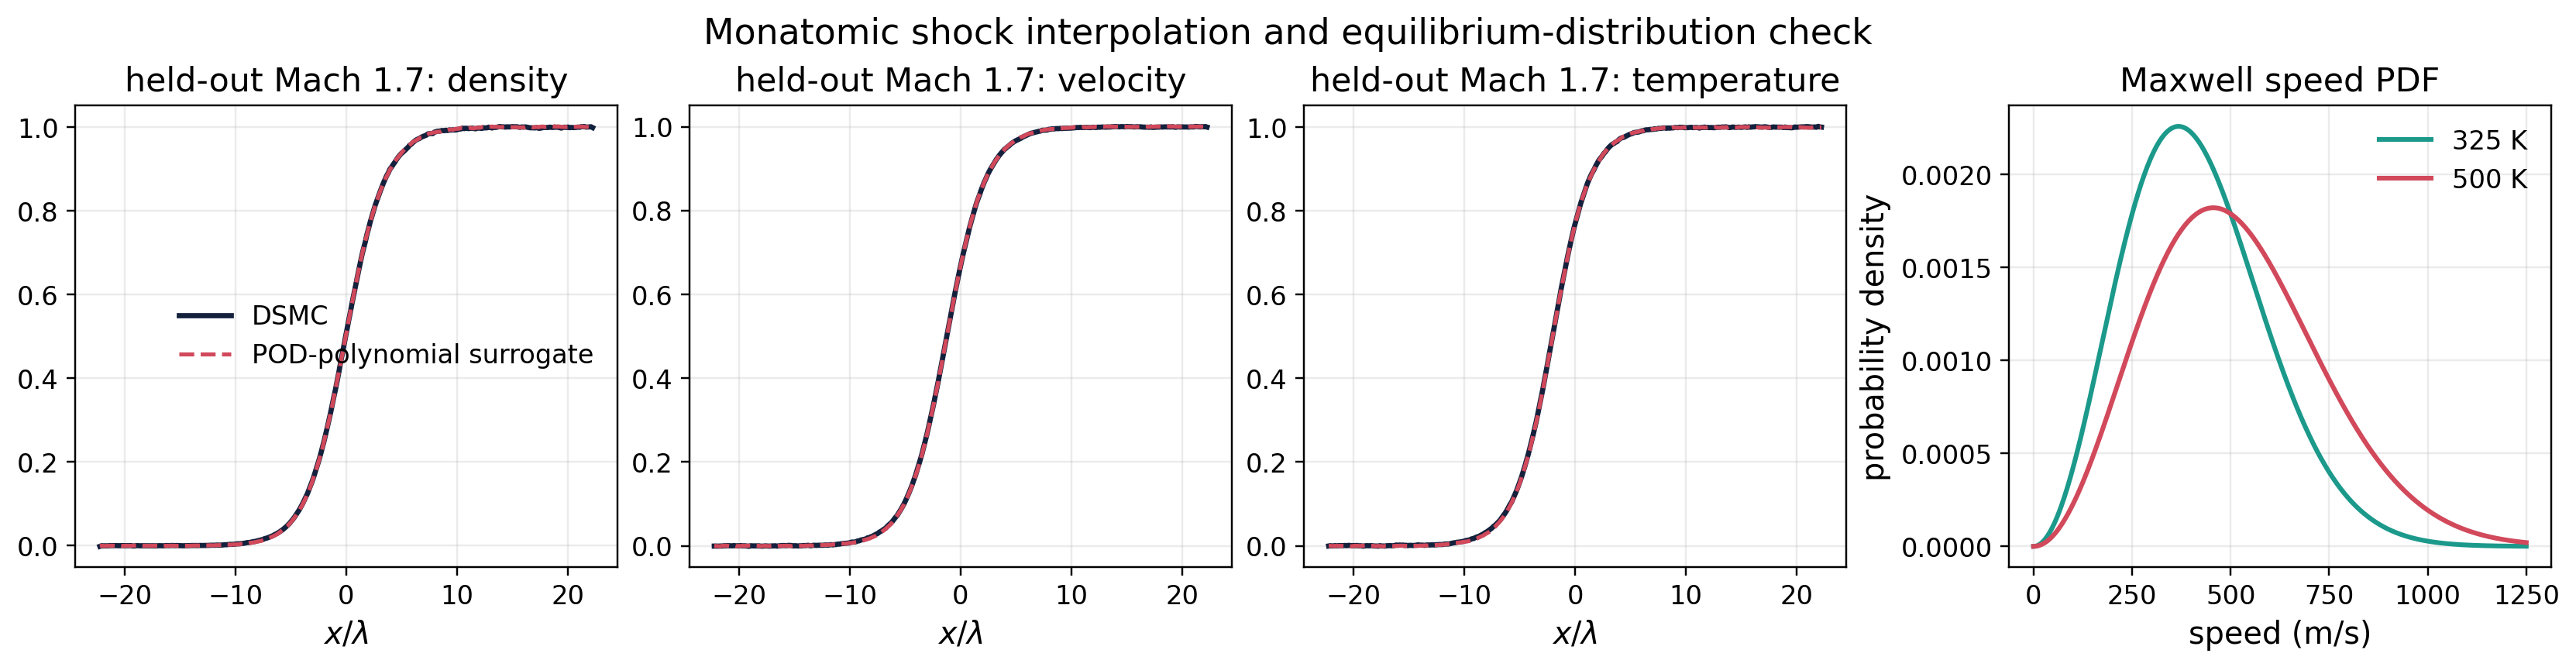

In [8]:
display(Image(filename=str(RESULTS / "monatomic_relaxation_reproduction.png")))

## 5. One-command reproduction and retained evidence

The following program rebuilds every metric and figure shown in this notebook. It stops if any primary cavity NRMSE exceeds 2% or any retained shock-profile relative $L_2$ exceeds 1.5%.

,value
cavity_100_ms_target_available,False
cavity_primary_max_nrmse_percent,1.281102
cavity_primary_mean_nrmse_percent,0.672364
data_manifest_sha256,455991685839806877a5456b2e0af3abf6340d568fa6fd...
diatomic_mach_2_target_available,False
figures_sha256,{'cavity_kn005_reproduction.png': '76b9b53a4da...
metrics_sha256,483e516e56423fa2bb5620e57095d897684620cf5bd837...
schema_version,1
shock_max_relative_l2_percent,1.018425
shock_mean_relative_l2_percent,0.423503


,case_family,lid_speed_ms,test_parameter,field,metric,value,normalization
0,cavity,10.0,Kn=0.05,u_ms,NRMSE_percent,8.953039e-01,lid_speed
1,cavity,10.0,Kn=0.05,v_ms,NRMSE_percent,1.281102e+00,lid_speed
2,cavity,10.0,Kn=0.05,temperature_k,NRMSE_percent,5.346154e-01,wall_delta_T
3,cavity,10.0,Kn=0.05,qx,NRMSE_percent,1.756426e+00,target_max_abs
4,cavity,10.0,Kn=0.05,qy,NRMSE_percent,6.482532e+00,target_max_abs
5,cavity,10.0,Kn=0.05,txy,NRMSE_percent,2.687131e+00,target_max_abs
6,cavity,10.0,Kn=0.5,u_ms,NRMSE_percent,8.116305e-01,lid_speed
7,cavity,10.0,Kn=0.5,v_ms,NRMSE_percent,7.837188e-01,lid_speed
8,cavity,10.0,Kn=0.5,temperature_k,NRMSE_percent,4.632078e-01,wall_delta_T
9,cavity,10.0,Kn=0.5,qx,NRMSE_percent,2.032655e+00,target_max_abs


FRESH figures from this run: <repository>\student_runs\week10_aescte_dsmc


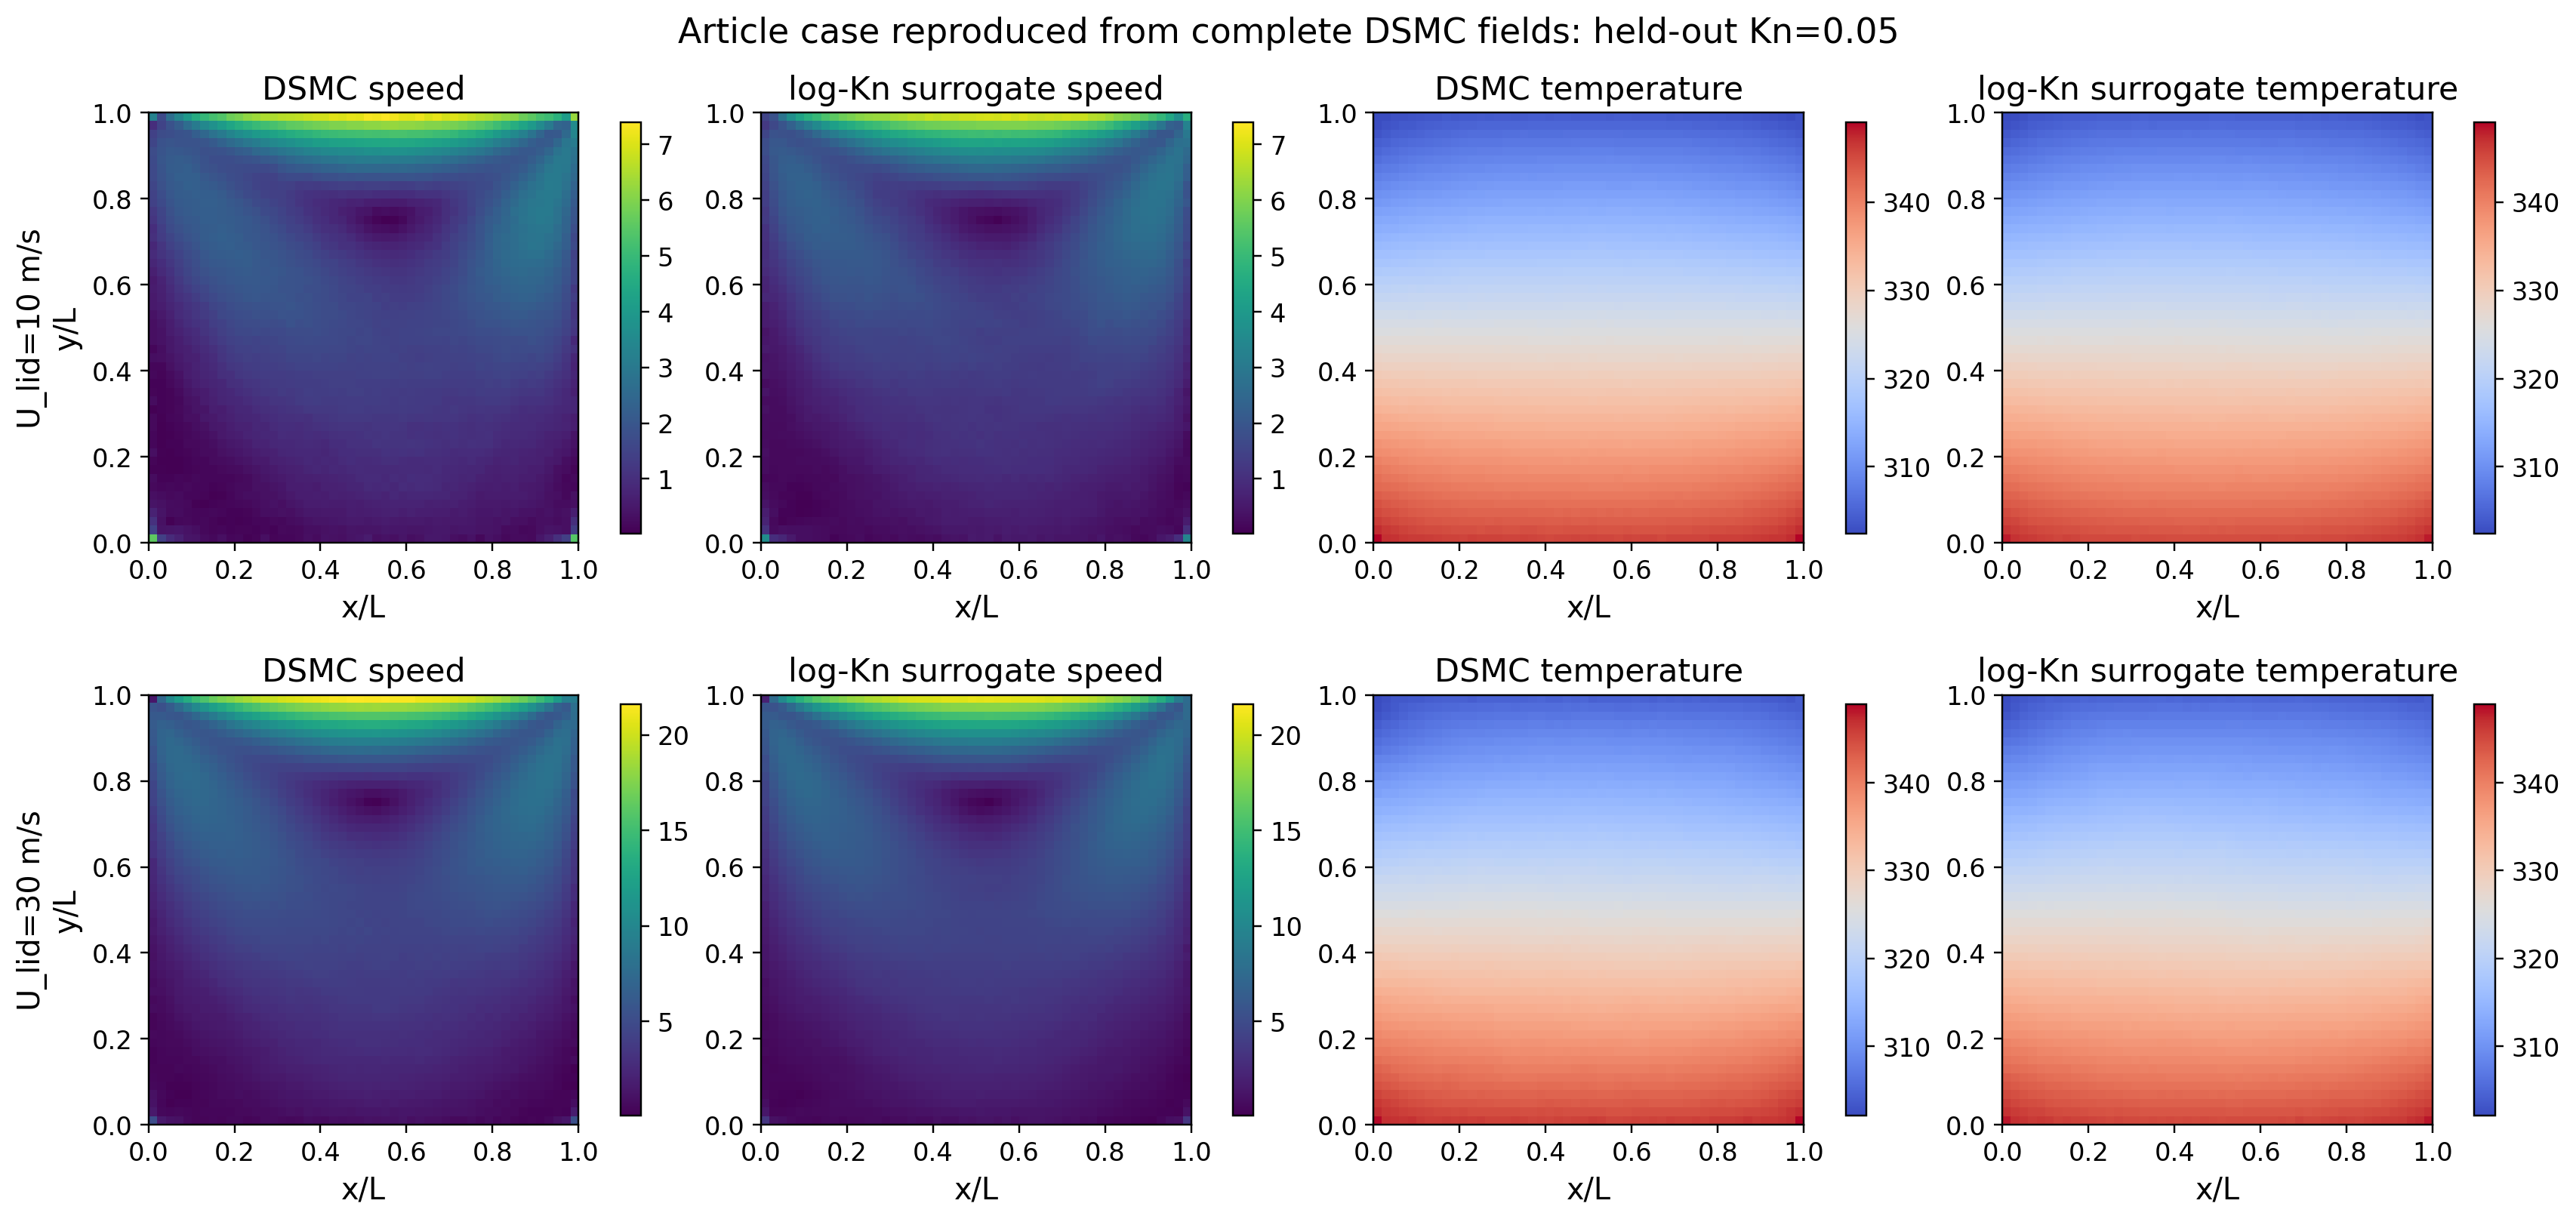

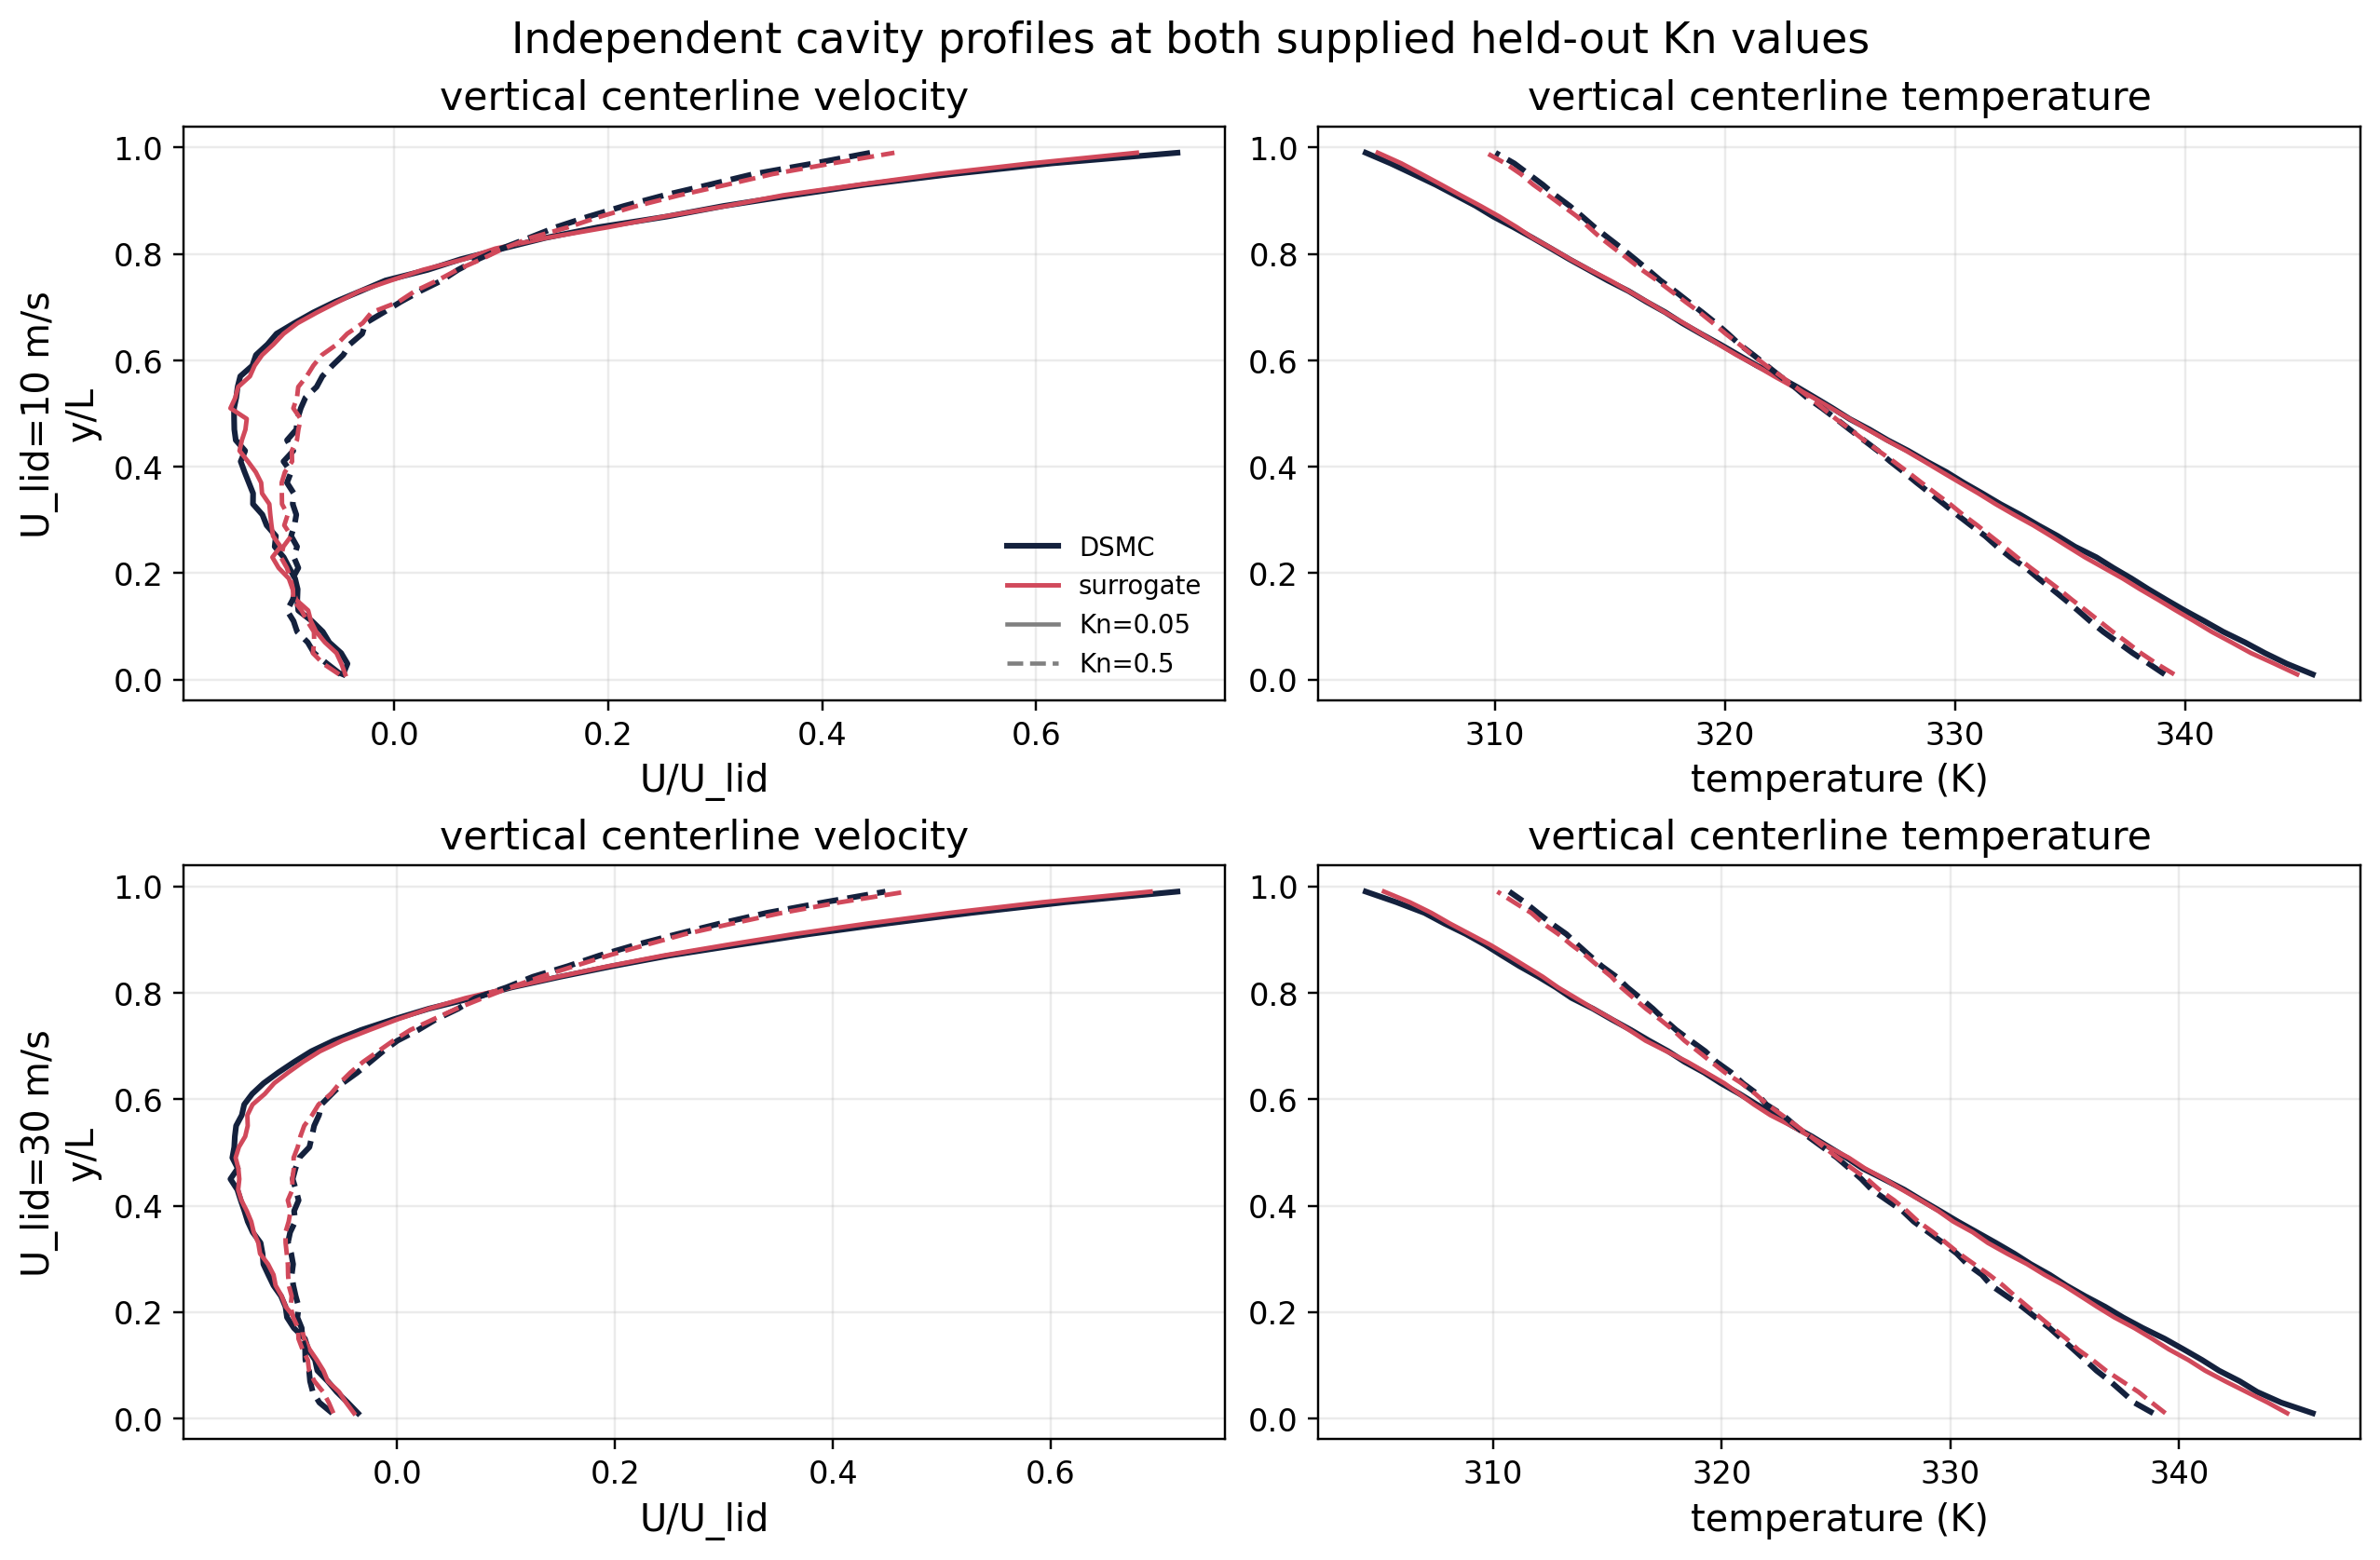

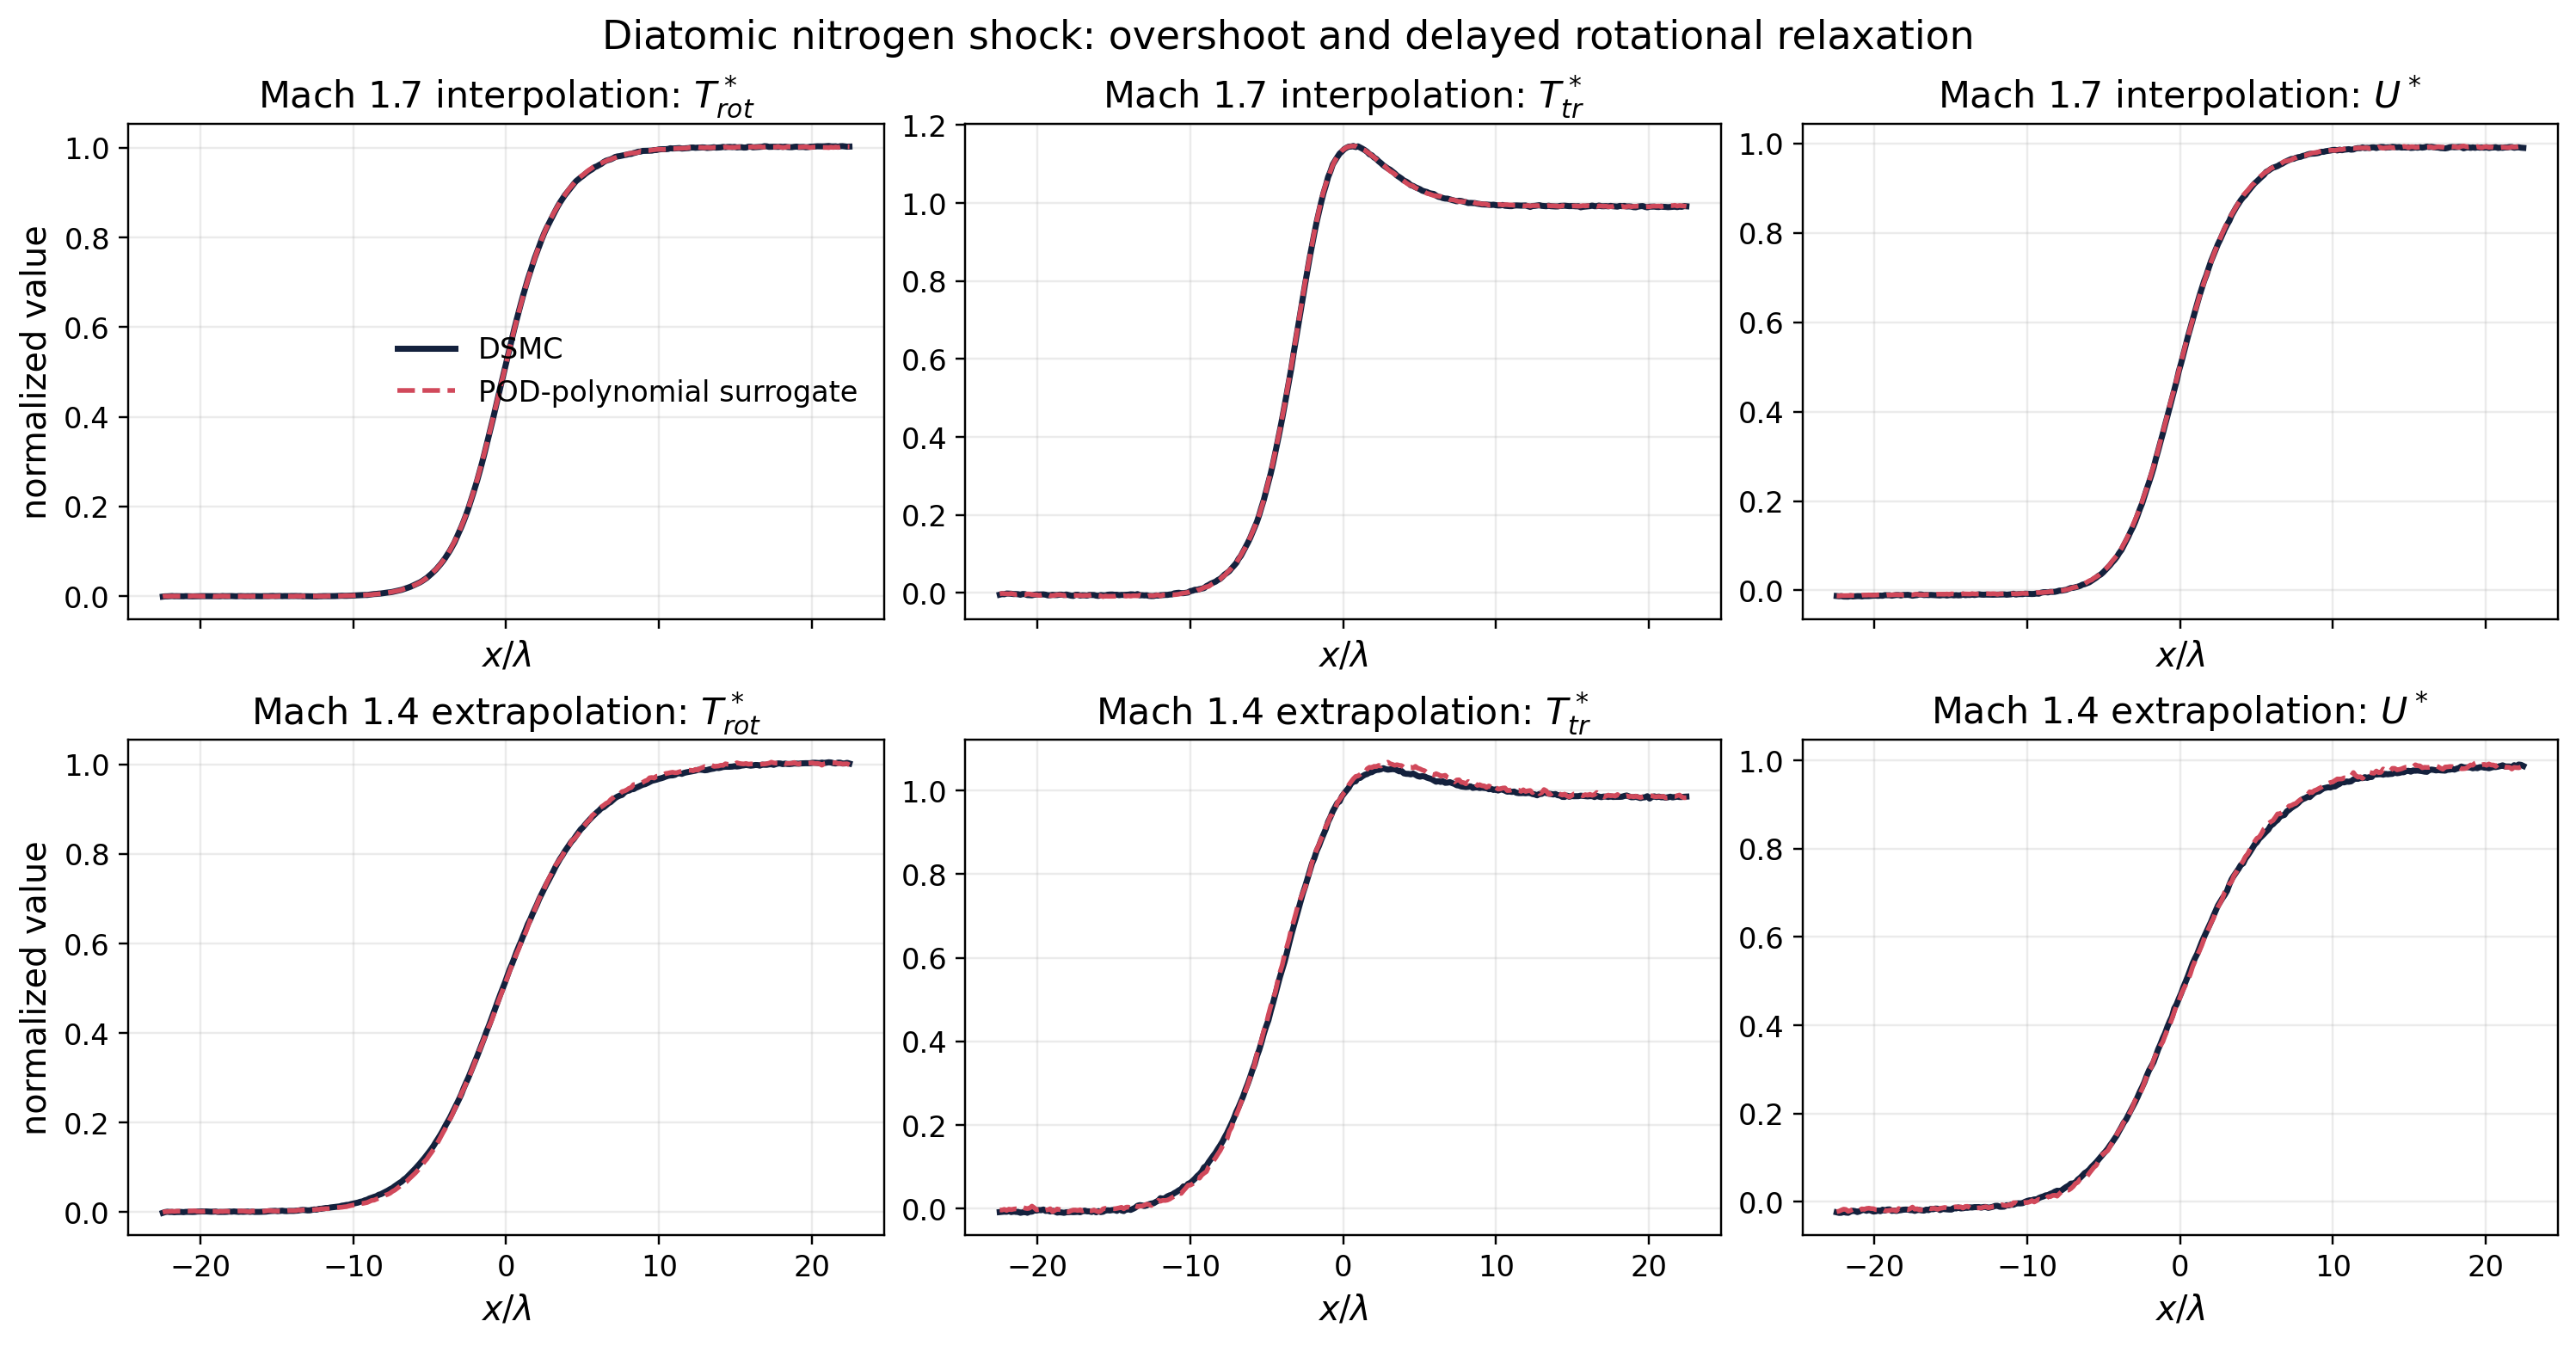

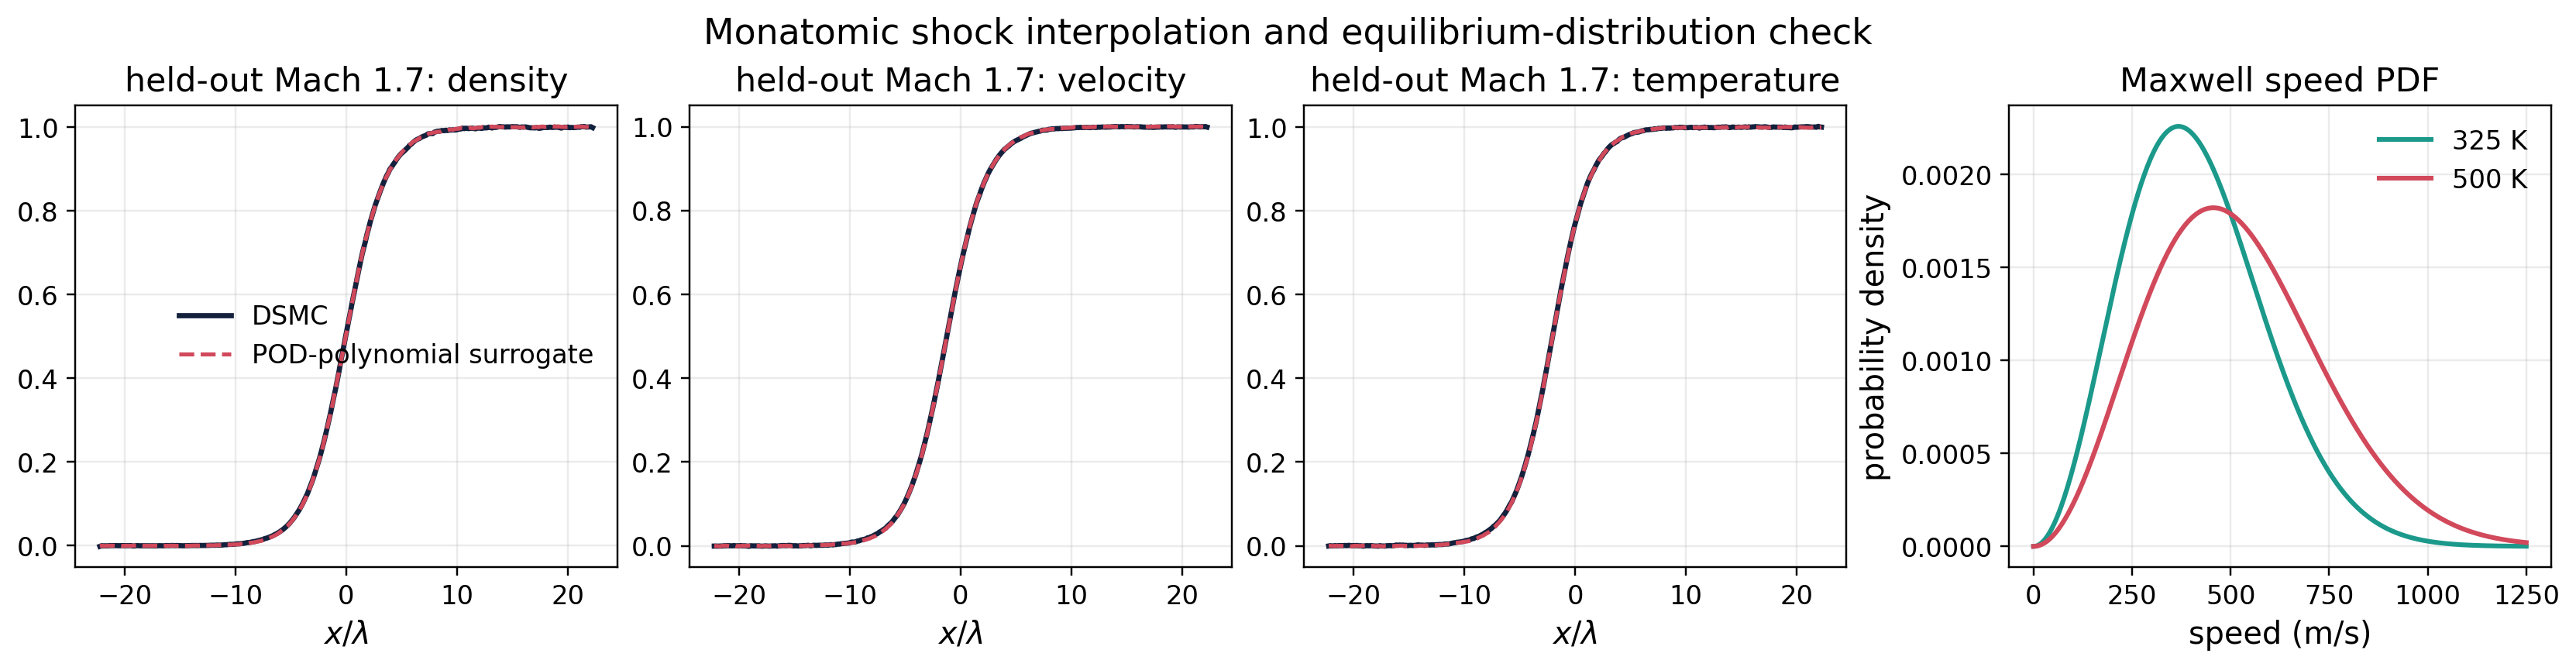

In [9]:
student_output = REPO_ROOT / "student_runs/week10_aescte_dsmc"
command = [_sys.executable, str(REPO_ROOT / "qa/run_week10_aescte_validation.py"), "--output-dir", str(student_output)]
_subprocess.run(command, check=True)
summary = json.loads((student_output / "validation_summary.json").read_text())
display(pd.Series(summary).to_frame("value"))
display(pd.read_csv(student_output / "week10_validation_metrics.csv"))

print('FRESH figures from this run:', student_output)
for filename in ('cavity_kn005_reproduction.png', 'cavity_validation_profiles.png',
                 'diatomic_shock_reproduction.png', 'monatomic_relaxation_reproduction.png'):
    generated_figure = student_output / filename
    if not generated_figure.is_file():
        raise FileNotFoundError('Fresh figure not generated: ' + str(generated_figure))
    display(Image(filename=str(generated_figure)))

## Submission

1. Explain why DSMC sampling uncertainty should be checked before ML error.
2. Derive the log-Kn weight for 0.05 and 0.5.
3. Report all primary cavity errors with their normalization scales.
4. Explain the translational-temperature overshoot.
5. Compare interpolation at Mach 1.7 with extrapolation at Mach 1.4.
6. Identify the two article claims that cannot be independently scored from the supplied data.
7. Propose one additional DSMC run that most improves the evidence, including its seed and resolution study.

## Worked audit and interpretation

Run these cells after the main lesson. They compute diagnostics from the objects above; they do not replace the frozen scientific protocol. Predict the result before running, then explain any failure using the stated metric and input information.

### Audit 1: Verify log-Knudsen weights against their analytical formula.

State which inputs and reference define this comparison. A failed check is a result to investigate, not permission to select new settings on the test cases.

In [10]:
from flowmllab.aescte_dsmc import CAVITY_TRAIN_KNUDSEN

weight_rows = []
for kn in CAVITY_TEST_KNUDSEN:
    analytic = (np.log10(kn) - np.log10(CAVITY_TRAIN_KNUDSEN[CAVITY_TRAIN_KNUDSEN < kn].max())) / (
        np.log10(CAVITY_TRAIN_KNUDSEN[CAVITY_TRAIN_KNUDSEN > kn].min())
        - np.log10(CAVITY_TRAIN_KNUDSEN[CAVITY_TRAIN_KNUDSEN < kn].max()))
    for lid in CAVITY_LID_SPEEDS_MS.astype(int):
        pred = cavity_predictions[(lid, float(kn))]
        lower = cavity_case(cavity, lid, pred["lower_knudsen"])
        upper = cavity_case(cavity, lid, pred["upper_knudsen"])
        manual = {f: (1 - analytic) * cavity[f][lower] + analytic * cavity[f][upper]
                  for f in ("u_ms", "v_ms", "temperature_k")}
        weight_rows.append({"U_lid": lid, "Kn*": kn, "Kn_l": pred["lower_knudsen"], "Kn_u": pred["upper_knudsen"],
                            "w (hand)": analytic, "w (module)": pred["weight"], "log10(5)": np.log10(5),
                            "max |hand - module| field": max(np.abs(manual[f] - pred[f]).max() for f in manual)})
display(pd.DataFrame(weight_rows))

,U_lid,Kn*,Kn_l,Kn_u,w (hand),w (module),log10(5),max |hand - module| field
0,10,0.05,0.01,0.1,0.69897,0.69897,0.69897,0.0
1,30,0.05,0.01,0.1,0.69897,0.69897,0.69897,0.0
2,10,0.50,0.10,1.0,0.69897,0.69897,0.69897,0.0
3,30,0.50,0.10,1.0,0.69897,0.69897,0.69897,0.0


### Audit 2: Read the error normalization before comparing velocity components.

State which inputs and reference define this comparison. A failed check is a result to investigate, not permission to select new settings on the test cases.

In [11]:
primary_table = cavity_metrics.copy()
primary_table["normalization scale"] = np.where(primary_table["field"] == "temperature_k", "50 K wall dT",
                                                "U_lid = " + primary_table["U_lid_m/s"].astype(str) + " m/s")
display(primary_table.pivot_table(index=["U_lid_m/s", "held_out_Kn"], columns="field",
                                  values="NRMSE_percent").round(3)[["u_ms", "v_ms", "temperature_k"]])
print("primary max / mean NRMSE (%):", round(cavity_metrics.NRMSE_percent.max(), 3), "/",
      round(cavity_metrics.NRMSE_percent.mean(), 3))
secondary = pd.read_csv(student_output / "week10_validation_metrics.csv").query("case_family == 'cavity' and field in ['qx', 'qy', 'txy']")
display(secondary.pivot_table(index=["lid_speed_ms", "test_parameter"], columns="field", values="value").round(2))

field                   u_ms   v_ms  temperature_k
U_lid_m/s held_out_Kn                             
10        0.05         0.895  1.281          0.535
          0.50         0.812  0.784          0.463
30        0.05         0.568  0.520          0.584
          0.50         0.622  0.473          0.532

primary max / mean NRMSE (%): 1.281 / 0.672


field                          qx     qy    txy
lid_speed_ms test_parameter                    
10.0         Kn=0.05         1.76   6.48   2.69
             Kn=0.5          2.03  14.99   8.91
30.0         Kn=0.05         0.92   6.26   2.04
             Kn=0.5          1.56  14.90  10.76

### Audit 3: Measure shock overshoot and the midpoint convention.

State which inputs and reference define this comparison. A failed check is a result to investigate, not permission to select new settings on the test cases.

In [12]:
def midpoint(x, profile):
    upstream, downstream = profile[:5].mean(), profile[-20:].mean()
    return x[np.argmax((profile - upstream) / (downstream - upstream) >= 0.5)]

overshoot_rows = []
for i, mach in enumerate(diatomic["mach"]):
    x = diatomic["x_over_lambda"][i]
    t_tr, t_rot = diatomic["translational_temperature"][i], diatomic["rotational_temperature"][i]
    peak = int(np.argmax(t_tr))
    overshoot_rows.append({"Mach": mach, "T_tr peak (normalized)": t_tr[peak], "peak x/lambda": x[peak],
                           "T_rot at T_tr peak": t_rot[peak], "x50 T_tr": midpoint(x, t_tr),
                           "x50 T_rot": midpoint(x, t_rot), "lag (lambda)": midpoint(x, t_rot) - midpoint(x, t_tr)})
display(pd.DataFrame(overshoot_rows).round(3))

,Mach,T_tr peak (normalized),peak x/lambda,T_rot at T_tr peak,x50 T_tr,x50 T_rot,lag (lambda)
0,1.4,1.054,2.627,0.731,-4.578,-0.075,4.503
1,1.5,1.087,1.726,0.692,-4.128,-0.075,4.053
2,1.6,1.118,1.126,0.655,-3.978,-0.075,3.903
3,1.7,1.146,0.675,0.615,-3.677,-0.075,3.602
4,1.8,1.171,0.375,0.577,-3.527,-0.075,3.452
5,1.9,1.192,0.075,0.529,-3.377,-0.075,3.302


### Audit 4: Compare interpolation with extrapolation for the same fields.

State which inputs and reference define this comparison. A failed check is a result to investigate, not permission to select new settings on the test cases.

In [13]:
ratio = shock_metrics.pivot(index="field", columns="task", values="relative_L2_percent")
ratio["extrapolation / interpolation"] = ratio["extrapolation"] / ratio["interpolation"]
display(ratio.round(3))
for mach, pred in ((1.7, pred_17), (1.4, pred_14)):
    target = int(np.flatnonzero(np.isclose(diatomic["mach"], mach))[0])
    true_peak = diatomic["translational_temperature"][target].max()
    predicted_peak = pred["translational_temperature"].max()
    print(f"Mach {mach}: T_tr overshoot peak DSMC {true_peak:.4f}, surrogate {predicted_peak:.4f}, "
          f"error in overshoot height {100 * (predicted_peak - true_peak) / (true_peak - 1):+.1f}%")

task,extrapolation,interpolation,extrapolation / interpolation
field,,,
normalized_velocity,0.926,0.291,3.180
rotational_temperature,0.630,0.142,4.432
translational_temperature,1.018,0.260,3.921


Mach 1.7: T_tr overshoot peak DSMC 1.1465, surrogate 1.1462, error in overshoot height -0.2%
Mach 1.4: T_tr overshoot peak DSMC 1.0537, surrogate 1.0681, error in overshoot height +26.9%
